In [1]:
import numpy as np                              
import matplotlib.pyplot as plt                 
from matplotlib.patches import FancyBboxPatch   
import smplotlib                                
out = "proposal_figures/"

# --- Flag colours (hex codes) ---
# asexual flag: black, grey, white, purple
ace_black = "#000000"
ace_grey = "#A3A3A3"
ace_white = "#FFFFFF"
ace_purple = "#800080"
# pansexual flag: pink, yellow, blue
pan_pink = "#FF218C"
pan_yellow = "#FFD800"
pan_blue = "#21B1FF"
# bisexual flag: magenta, blue (used in Figure 3)
bi_magenta = "#D60270"
bi_blue = "#0038A8"

E_H = 13.6     # H ionisation
E_He2 = 54.4   # He II lines
E_Ne5 = 97.1   # Ne3+ -> Ne4
hc = 12398.4   # Planck constant x speed of light in eV*Angstrom

findfont: Failed to find font weight normal, now using 500.


In [2]:
dt = 30
m_new = np.array([1.6, 2.3, 1.2, 1.9, 0.9])  # stellar mass formed in each of the last 5 steps (made-up example values)
colours = [ace_purple, pan_pink, pan_yellow, pan_blue, ace_grey]   # one colour per burst = its metallicity Z_1 ... Z_5
age = (np.arange(5) + 0.5) * dt             # middle of each step: 14.8, 44.4, 74.0, ... Myr (where the points go)

In [3]:
# --- SED of each burst for panel 3 ---
lE = np.linspace(0.6, 2.2, 600)
lH = np.log10(E_H)                          # position of 13.6 eV on this log axis
lHe = np.log10(E_He2)                       # position of 54.4 eV

seds = []  # empty list; we add one SED per burst
base = [0.4, 0.6, 0.9, 1.1, 1.5]       
drop = [0.3, 2.0, 2.5, 3.0, 3.5]
steep = [0.8, 1.3, 1.7, 1.9, 2.1]   

for k in range(5):                          # k = 0, 1, 2, 3, 4  
    y = -(base[k] + 0.5 * (lE - lE[0]))     # UV part: a straight, slowly falling line
    above = lE >= lH                        # mask: energies at or above 13.6 eV
    y[above] = -(base[k] + 0.5 * (lH - lE[0]) + drop[k] + steep[k] * (2.5 * (lE[above] - lH))**1.25)   # drop, then a curved fall
    seds.append(y)
total_sed = np.log10(np.sum(10**np.array(seds), axis=0))

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight bold, now using 800.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.


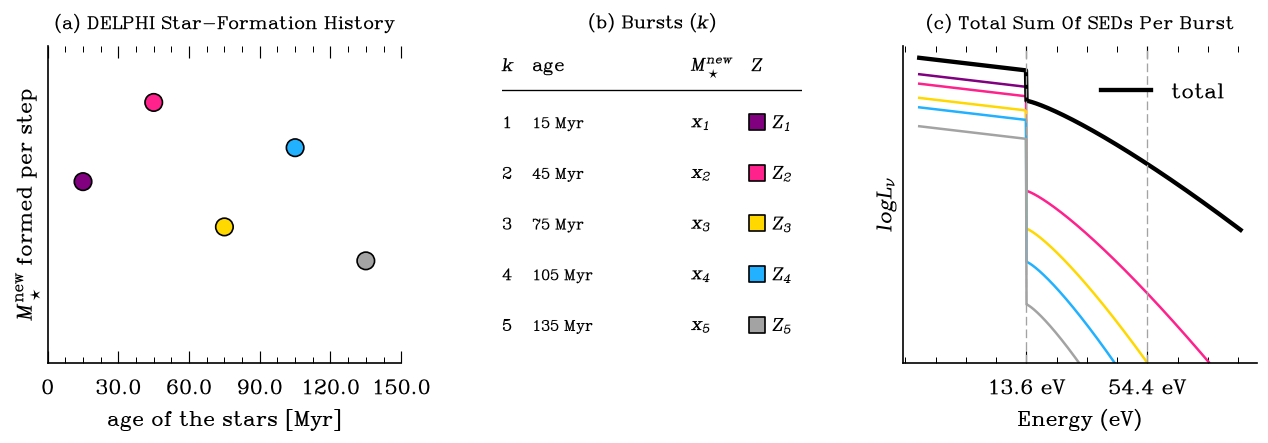

In [4]:
# ===== Draw Figure 2 =====
fig = plt.figure(figsize=(13, 5.6))
# A grid of 2 rows x 3 columns: top row = the three panels, bottom row = the equation (spans all columns)
gs = fig.add_gridspec(2, 3, height_ratios=[3, 1], width_ratios=[1, 0.85, 1], hspace=0.45, wspace=0.3)

#Panel 1
ax1 = fig.add_subplot(gs[0, 0])                       
ax1.scatter(age, m_new, s=110, c=colours, edgecolor=ace_black, zorder=3)   

ticks = np.arange(6) * dt                   
ax1.set_xticks(ticks, ["0", "30.0", "60.0", "90.0", "120.0", "150.0"])
ax1.set_xlim(0, 5 * dt)
ax1.set_ylim(0, 2.8)
ax1.set_yticks([])                                   
ax1.set_xlabel("age of the stars [Myr]")
ax1.set_ylabel(r"$M_\star^{\rm new}$ formed per step")
ax1.set_title("(a) DELPHI Star-Formation History", fontsize=13)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

#Panel 2
ax2 = fig.add_subplot(gs[0, 1])
ax2.axis("off")
ax2.set_title(r"(b) Bursts ($k$)", fontsize=13)
ax2.text(0.0, 0.92, "$k$", fontsize=13, transform=ax2.transAxes)
ax2.text(0.1, 0.92, "age", fontsize=13, transform=ax2.transAxes)
ax2.text(0.63, 0.92, r"$M_\star^{new}$", fontsize=13, transform=ax2.transAxes)
ax2.text(0.83, 0.92, "$Z$", fontsize=13, transform=ax2.transAxes)

ax2.plot([0, 1], [0.86, 0.86], color=ace_black, lw=0.8, transform=ax2.transAxes)   # line under the headings

ages = ["%.0f" % a for a in age]                    # age of each burst: 15, 44, 74, 104, 133 Myr
for k in range(5):
    y = 0.74 - 0.16 * k                               # each row is 0.16 lower than the one before
    ax2.text(0.0, y, str(k + 1), fontsize=12, transform=ax2.transAxes)
    ax2.text(0.1, y, ages[k] + " Myr", fontsize=11, transform=ax2.transAxes)
    ax2.text(0.63, y, "$x_%d$" % (k + 1), fontsize=13, transform=ax2.transAxes)
    ax2.scatter([0.85], [y + 0.02], s=90, c=colours[k], marker="s", transform=ax2.transAxes)   # coloured square
    ax2.text(0.9, y, "$Z_%d$" % (k + 1), fontsize=13, transform=ax2.transAxes)

#Panel 3
ax3 = fig.add_subplot(gs[0, 2])
for k in range(5):
    y = seds[k].copy()                                # copy, so we don't change the stored SED
    y[y < -6.5] = np.nan                              # hide the part below the bottom of the plot
    ax3.plot(lE, y, color=colours[k], lw=1.5)
y = total_sed.copy()
y[y < -6.5] = np.nan
ax3.plot(lE, y, color=ace_black, lw=2.6, label="total")
ax3.axvline(lH, color=ace_grey, ls="--", lw=0.8)      # 13.6 eV
ax3.axvline(lHe, color=ace_grey, ls="--", lw=0.8)     # 54.4 eV
ax3.set_xticks([lH, lHe], ["13.6 eV", "54.4 eV"])
ax3.set_yticks([])
ax3.set_ylim(-6.5, 0.2)
ax3.set_xlabel("Energy (eV)")
ax3.set_ylabel(r"$log L_\nu$")
ax3.set_title("(c) Total Sum Of SEDs Per Burst", fontsize=13)
ax3.legend(loc="upper right", frameon=False)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)


fig.savefig(out + "fig2_method.pdf", bbox_inches="tight")
fig.savefig(out + "fig2_method.png", dpi=200, bbox_inches="tight")
plt.show()